# Week 12 In-Class Demo 2
## Tuning Regularized Regression Models

We continue with the **same health dataset, same cost target, same feature set, and same protected test set logic** from Demo 1.

The question now is:

> **How do we choose regularization settings systematically rather than guessing?**

## Learning objectives
By the end of this in-class demonstration, students should be able to:

1. **Distinguish parameters from hyperparameters**, using regression coefficients, `alpha`, and ElasticNet `l1_ratio` as examples.
2. **Explain three-fold cross-validation in plain language** and describe why the protected test set remains outside the tuning process.
3. **Explain why preprocessing must stay inside the pipeline** during cross-validation to prevent validation leakage.
4. **Interpret Ridge and Lasso `alpha`** as the strength of the regularization penalty.
5. **Use regression metrics correctly during tuning**, including scikit-learn's `neg_root_mean_squared_error` convention.
6. **Calculate the computational workload of a search** using candidate combinations × cross-validation folds.
7. **Use `GridSearchCV` to compare every listed combination** in a small, purposeful regression search space.
8. **Explain when `RandomizedSearchCV` is more practical** than an exhaustive grid and how `n_iter` controls the search budget.
9. **Inspect the complete search results**, rather than reporting only `best_params_` or the winning row.
10. **Select a workflow using cross-validation and evaluate it once on protected test data** using MAE, RMSE, and R².
11. **Judge whether a tuned improvement is practically meaningful** by considering stability, simplicity, interpretability, computation, and business use.
12. **Communicate the tuning process to a non-technical manager** without relying only on Python function names.
13. **Transfer the tuning workflow to the Term Project Salary-regression task** using a reproducible and leakage-safe process.

> **Student success indicator:** A student should be able to explain how candidate settings were compared, why one setting was selected, and whether the resulting improvement is important enough to justify the final model choice.

## BBA mental model
A hyperparameter is a business analyst's setting chosen before model fitting. For regularized regression, `alpha` controls penalty strength.

- very small `alpha`: behave more like ordinary linear regression;
- larger `alpha`: shrink coefficients more aggressively;
- too much shrinkage: the model can become too simple.

Cross-validation lets candidate settings compete across repeated validation folds. Grid search and randomized search automate the repetition.

## Week 12 resources
- [Course Delivery Plan](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=42c15f8c0a8a487a9c578486-56)
- [Lecture 21–22 recording](https://nait.video.yuja.com/V/Video?v=1347378&node=7565673&a=140557614)
- [Lecture 21–22 presentation](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=content&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551463)
- [Lecture 21 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture21_Multiple_Regression.ipynb)
- [Lecture 22 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture22_Regression_Tuning.ipynb)
- [Lecture 21–22 student workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture21_22_workbook.ipynb)
- [Workbook solution](https://colab.research.google.com/drive/1OdWqGU-jSto8-I49bnP2NOCQAwPfYdZx?usp=sharing)
- [O’Reilly: *Machine Learning with Python for Everyone*](https://learning.oreilly.com/library/view/machine-learning-with/9780134845708/)
  - **Chapter 9: More Regression Methods**
  - **Chapter 11: Tuning Hyperparameters and Pipelines**
- [Machine Learning Assignment 2](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551201)
- [Term Project](https://lms.nait.ca/d2l/common/dialogs/quickLink/quickLink.d2l?ou=182241&type=dropbox&rcode=EE964922-8905-4C5B-ACC8-340F77B2A0B1-551222)

## What to focus on
- keep the final test data outside tuning;
- tune the **complete pipeline**, not preprocessed data created in advance;
- understand `alpha` before searching values;
- use a regression scoring metric correctly;
- compare GridSearchCV with RandomizedSearchCV;
- recognize that the best CV setting is an estimate, not a permanent truth.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
RANDOM_STATE=42

## Tuning vocabulary before the code
| Term | Plain-language meaning |
|---|---|
| **Parameter** | Value learned by fitting, such as a regression coefficient |
| **Hyperparameter** | Analyst-specified setting, such as Ridge `alpha` |
| **Candidate** | One hyperparameter combination being evaluated |
| **Fold** | One temporary validation partition used during cross-validation |
| **Search space** | All candidate settings the analyst allows the search to consider |
| **Best setting** | Candidate with the best average CV score under the chosen metric |

The “best setting” is best **within the search space and validation design we specified**. It is not proof that no better setting exists anywhere.

## Common mistakes to avoid
- Using the protected test set to choose `alpha`.
- Preprocessing the complete dataset before cross-validation.
- Thinking `-510` is better than `-420` for negative RMSE.
- Treating the winning candidate as globally optimal.
- Building an enormous grid without calculating candidate combinations × folds.
- Reporting only `best_params_` without examining the size and stability of the improvement.
- Assuming tuning must produce a dramatic gain.

## 1. Recreate the same analytical data
Demo 2 repeats Demo 1 cleaning so the notebook can run independently. No new cleaning rules are introduced.

In [10]:
DATA_PATH="healthcare_readmission.csv"
from pathlib import Path

if not Path(DATA_PATH).exists():
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. Place the CSV in the same folder as this notebook."
    )

df_raw = pd.read_csv(DATA_PATH, low_memory=False)
required_columns = {
    "patient_id", "age", "gender", "region", "bmi", "systolic_bp",
    "cholesterol_mmol_l", "hba1c_pct", "smoker_status", "activity_level",
    "chronic_conditions", "prior_admissions", "avg_visit_cost",
    "insurance_type", "appointment_wait_days", "missed_appointments",
    "readmitted_30d"
}
missing_columns = sorted(required_columns - set(df_raw.columns))
if missing_columns:
    raise ValueError(f"The CSV is missing required columns: {missing_columns}")
df=df_raw.copy().replace(["","NA","N/A","unknown","Unknown"],np.nan).drop_duplicates().copy()
nums=["age","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","chronic_conditions","prior_admissions","avg_visit_cost","appointment_wait_days","missed_appointments"]
for col in nums: df[col]=pd.to_numeric(df[col],errors="coerce")
ranges={"age":(18,100),"bmi":(12,70),"systolic_bp":(70,250),"cholesterol_mmol_l":(1,15),"hba1c_pct":(3,20),"chronic_conditions":(0,15),"prior_admissions":(0,20),"avg_visit_cost":(0,20000),"appointment_wait_days":(0,365),"missed_appointments":(0,30)}
for col,(lo,hi) in ranges.items(): df.loc[df[col].notna() & ~df[col].between(lo,hi),col]=np.nan
cats=["gender","region","smoker_status","activity_level","insurance_type"]
for col in cats: df[col]=df[col].astype("string").str.strip().str.lower()
maps={"gender":{"f":"Female","female":"Female","m":"Male","male":"Male","nb":"Non-binary","nonbinary":"Non-binary","non-binary":"Non-binary"},"region":{"edmonton":"Edmonton","edm":"Edmonton","calgary":"Calgary","yyc":"Calgary","central alberta":"Central Alberta","northern alberta":"Northern Alberta","north":"Northern Alberta","southern alberta":"Southern Alberta","south":"Southern Alberta"},"smoker_status":{"never":"Never","n":"Never","former":"Former","current":"Current","y":"Current"},"activity_level":{"low":"Low","moderate":"Moderate","high":"High"},"insurance_type":{"employer":"Employer","govt":"Government","government":"Government","private":"Private","un-insured":"Uninsured","uninsured":"Uninsured"}}
for col,m in maps.items():
    df[col]=df[col].map(m).astype(object); df[col]=df[col].where(pd.notna(df[col]),np.nan)
print("Raw rows:",len(df_raw),"Clean analytical rows:",len(df))

Raw rows: 120500 Clean analytical rows: 120000


## 2. Recreate the same regression problem and preprocessing
The target remains `avg_visit_cost`. The test set remains protected while tuning takes place inside the training data.

### Classroom runtime choice
The full cleaned dataset contains more than 116,000 records with a valid cost target. Repeating Lasso and ElasticNet across many folds and settings on every training row would make the live demonstration unnecessarily slow.

This notebook therefore uses a reproducible **30,000-row development sample** from the training partition for cross-validation and tuning. The protected test set remains the full test partition. This is a teaching-time compromise, not a claim that smaller data are always preferable. In a production project, computation, validation design, and available infrastructure should determine the search plan.

In [12]:
target="avg_visit_cost"
features=["age","gender","region","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","smoker_status","activity_level","chronic_conditions","prior_admissions","insurance_type","appointment_wait_days","missed_appointments"]
model_df=df[features+[target]].copy()
model_df=model_df.dropna(subset=[target])
X=model_df[features]; y=model_df[target]
X_train_full,X_test,y_train_full,y_test=train_test_split(X,y,test_size=.2,random_state=RANDOM_STATE)
# Tuning on all 93,000+ training rows is computationally heavy for an in-class demo.
# Use a reproducible 30,000-row development sample for CV/search, while keeping
# the full protected test set for the final evaluation.
if len(X_train_full) > 30000:
    dev_index = X_train_full.sample(n=30000, random_state=RANDOM_STATE).index
    X_train = X_train_full.loc[dev_index].copy()
    y_train = y_train_full.loc[dev_index].copy()
else:
    X_train, y_train = X_train_full.copy(), y_train_full.copy()
num=["age","bmi","systolic_bp","cholesterol_mmol_l","hba1c_pct","chronic_conditions","prior_admissions","appointment_wait_days","missed_appointments"]
cat=["gender","region","smoker_status","activity_level","insurance_type"]
pre=ColumnTransformer([("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),num),("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),cat)])
print("Full training rows:",len(X_train_full))
print("CV/search development rows:",len(X_train))
print("Protected test rows:",len(X_test))

Full training rows: 93248
CV/search development rows: 30000
Protected test rows: 23313


## Why tune on training data only?
Tuning is part of model development. Every time we compare alpha values, we are learning something about which modeling choice works better.

If the protected test set participates in that choice, the test set is no longer independent. That is why cross-validation happens inside the training/development data and the test set waits until the end.

## 3. Understand `alpha` before tuning it
For Ridge and Lasso, `alpha` controls regularization strength.

We will search values across different orders of magnitude: `0.01`, `0.1`, `1`, `10`, and `100`.

This is often more informative than testing `1, 2, 3, 4, 5`, because useful penalty strengths can differ by factors of 10.

## Check-in 1: What happens as Ridge alpha increases?

<details><summary><strong>Reveal solution</strong></summary>

Coefficient magnitudes are generally pushed closer to zero. The model becomes more constrained. Moderate shrinkage can improve generalization, but excessive shrinkage can underfit and increase prediction error.

</details>

## Cross-validation for regression: a three-round mental model
This classroom notebook uses **three-fold** CV for runtime.

Think of the 30,000-row development sample as three groups:

- Round 1: train on groups B+C, validate on A.
- Round 2: train on groups A+C, validate on B.
- Round 3: train on groups A+B, validate on C.

Each candidate `alpha` receives three validation RMSE values, which are averaged. The protected test set is not one of these groups.

## Check-in: Why was Demo 2 reduced to 30,000 development rows?

<details><summary><strong>Reveal explanation</strong></summary>

The complete cleaned dataset is large enough that repeatedly fitting Lasso and ElasticNet over many settings can slow a live class substantially. A fixed 30,000-row development sample makes the demonstration practical while preserving the separate full test partition.

This is a **teaching-runtime decision**. For a real project, the sampling choice, computational budget, infrastructure, and validation design should be justified explicitly.

</details>

## 4. Build a Ridge pipeline and cross-validation plan
We use three-fold `KFold` because the target is continuous. Unlike classification, there is no class proportion to preserve with `StratifiedKFold`.

The complete preprocessing pipeline stays inside every fold so medians, scales, and one-hot categories are learned only from each fold's training portion.

In [19]:
ridge_pipe=Pipeline([("preprocess",pre),("regressor",Ridge())])
cv=KFold(n_splits=3,shuffle=True,random_state=RANDOM_STATE)
param_grid={"regressor__alpha":[0.01,0.1,1.0,10.0,100.0]}
print("Candidates:",len(param_grid["regressor__alpha"]),"x folds: 3 =",len(param_grid["regressor__alpha"])*3,"validation fits")

Candidates: 5 x folds: 3 = 15 validation fits


## Why RMSE is our search metric
We need one metric to rank candidates consistently. This notebook uses RMSE because large cost errors receive extra weight.

That does not mean RMSE is universally best. If a business cared about the typical dollar miss and wanted less sensitivity to unusual large errors, MAE might be a useful selection metric instead.

The decision metric should reflect the practical cost of prediction errors.

## 5. A scikit-learn scoring detail: negative RMSE
Scikit-learn's search tools are designed so **larger scores are better**. Error metrics work in the opposite direction because smaller error is better.

Therefore scikit-learn provides `neg_root_mean_squared_error`. During the search, an RMSE of 500 is represented as `-500`, which is better than `-700` because `-500` is larger.

After the search, we multiply by `-1` when we want to display an ordinary positive RMSE for business interpretation.

In [22]:
ridge_search=GridSearchCV(ridge_pipe,param_grid,scoring="neg_root_mean_squared_error",cv=cv,n_jobs=-1,refit=True,return_train_score=True)
ridge_search.fit(X_train,y_train)
print("Best alpha:",ridge_search.best_params_["regressor__alpha"])
print("Best mean CV RMSE:",round(-ridge_search.best_score_,2))

Best alpha: 100.0
Best mean CV RMSE: 345.96


### How to interpret the winning alpha
The selected `alpha` is the candidate with the lowest average validation RMSE among the values we tested. It should not be described as “the mathematically perfect alpha.”

A nearby alpha with almost the same CV RMSE may be practically equivalent. Always inspect the full results table before attaching importance to a single winning value.

## Check-in 2: Which score is better?
Search result A has `-420` and result B has `-510` for negative RMSE. Which does GridSearchCV prefer?

<details><summary><strong>Reveal solution</strong></summary>

GridSearchCV prefers `-420` because it is the larger score. Converting back to normal error, the candidates have RMSE 420 and 510, and **420 is the lower error**.

</details>

## 6. Inspect every candidate
Do not stop at `best_params_`. The results table shows whether several alpha values are effectively tied and whether training/validation performance separates as regularization changes.

,alpha,CV_RMSE,Train_RMSE,CV_SD
0,0.01,345.96,345.59,0.57
1,0.10,345.96,345.59,0.57
2,1.00,345.96,345.59,0.57
3,10.00,345.96,345.59,0.57
4,100.00,345.96,345.59,0.57


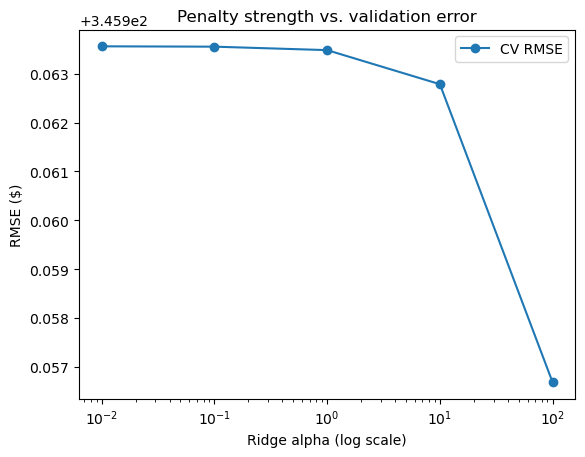

In [26]:
ridge_results=pd.DataFrame(ridge_search.cv_results_)
ridge_view=pd.DataFrame({
    "alpha":ridge_results["param_regressor__alpha"].astype(float),
    "CV_RMSE":-ridge_results["mean_test_score"],
    "Train_RMSE":-ridge_results["mean_train_score"],
    "CV_SD":ridge_results["std_test_score"]
}).sort_values("alpha")
display(ridge_view.round(2))
# Some Matplotlib versions can emit internal pyparsing deprecation warnings
# while rendering labels. These warnings come from the plotting dependency, not
# from the regression workflow, so suppress that specific warning locally.
import warnings
try:
    from pyparsing import PyparsingDeprecationWarning
except ImportError:
    PyparsingDeprecationWarning = DeprecationWarning

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=PyparsingDeprecationWarning)
    plt.plot(ridge_view["alpha"], ridge_view["CV_RMSE"], marker="o", label="CV RMSE")
    plt.xscale("log")
    plt.xlabel("Ridge alpha (log scale)")
    plt.ylabel("RMSE ($)")
    plt.title("Penalty strength vs. validation error")
    plt.legend()
    plt.show()

## Before comparing Ridge, Lasso, and ElasticNet
This comparison changes the **model family and hyperparameters** while keeping the data, preprocessing, folds, and evaluation metric consistent.

That consistency makes the comparison easier to explain. If we changed the data-cleaning rules at the same time, we could not tell whether performance changed because of the model or because of the data.

## 7. Tune Lasso and ElasticNet
Lasso has `alpha`. ElasticNet has both `alpha` and `l1_ratio`.

`l1_ratio` controls the mixture:
- closer to 1 gives more Lasso-style penalty;
- closer to 0 gives more Ridge-style penalty.

We keep the teaching grids deliberately small so students can calculate the workload and understand every candidate.

In [29]:
searches={}
lasso=Pipeline([("preprocess",pre),("regressor",Lasso(max_iter=10000))])
lasso_grid={"regressor__alpha":[0.1,1,10]}
searches["Lasso"]=GridSearchCV(lasso,lasso_grid,scoring="neg_root_mean_squared_error",cv=cv,n_jobs=-1).fit(X_train,y_train)

enet=Pipeline([("preprocess",pre),("regressor",ElasticNet(max_iter=10000))])
enet_grid={"regressor__alpha":[0.1,1,10],"regressor__l1_ratio":[0.2,0.8]}
searches["ElasticNet"]=GridSearchCV(enet,enet_grid,scoring="neg_root_mean_squared_error",cv=cv,n_jobs=-1).fit(X_train,y_train)

summary=[{"model":"Ridge","CV_RMSE":-ridge_search.best_score_,"settings":str(ridge_search.best_params_) }]
for name,s in searches.items(): summary.append({"model":name,"CV_RMSE":-s.best_score_,"settings":str(s.best_params_)})
pd.DataFrame(summary).sort_values("CV_RMSE").round(2)

,model,CV_RMSE,settings
1,Lasso,345.89,{'regressor__alpha': 1}
2,ElasticNet,345.93,"{'regressor__alpha': 0.1, 'regressor__l1_ratio..."
0,Ridge,345.96,{'regressor__alpha': 100.0}


## Check-in 3: Why not use the test set to pick Ridge vs. Lasso vs. ElasticNet?

<details><summary><strong>Reveal explanation</strong></summary>

If we choose the model family after repeatedly comparing test performance, the test set becomes part of development. The reported test result then looks more independent than it really is.

Use training-data validation to choose the workflow. Reserve the test set for the final evaluation of the selected approach.

</details>

## Grid search versus randomized search
A useful BBA comparison:

| GridSearchCV | RandomizedSearchCV |
|---|---|
| Evaluates every listed combination | Samples a fixed number of combinations |
| Easy to explain for a small grid | Useful when the space is large |
| Cost grows rapidly as dimensions are added | Analyst controls the search budget with `n_iter` |
| Exhaustive only within the listed grid | May miss the best candidate in the broader space |

Neither method guarantees the best possible real-world model. Both provide structured ways to allocate search effort.

## 🎥 Short theory video: Grid Search vs. Random Search
Run the video cell below before comparing the two search methods.

**Video:** Hyperparameters Tuning: Grid Search vs Random Search by DataMListic, approximately **3 minutes 15 seconds**.

### While watching, focus on:
1. Which method evaluates every listed combination?
2. Which method lets the analyst set a search budget?
3. Why can an exhaustive grid become impractical?

If embedded playback is blocked, use the fallback link:

[Open the video on YouTube](https://www.youtube.com/watch?v=G-fXV-o9QV8)

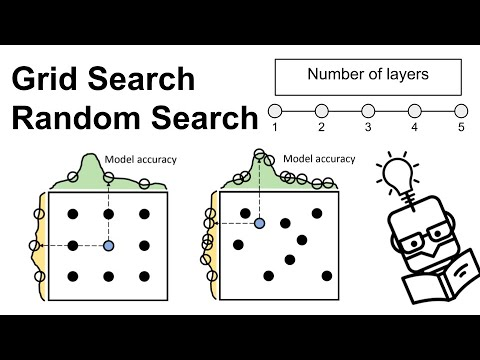

In [33]:
# Embedded YouTube video for Jupyter / Google Colab.
from IPython.display import YouTubeVideo, display

display(YouTubeVideo("G-fXV-o9QV8", width=800, height=450))

## Video check-in
A search problem has 4 hyperparameters with 10 listed choices each.

1. How many combinations are in a full grid?
2. Why might randomized search be attractive?

<details><summary><strong>Reveal solution</strong></summary>

1. A full grid contains `10 × 10 × 10 × 10 = 10,000` combinations. With three CV folds, that would require 30,000 validation fits before any final refit.
2. Randomized search can test a fixed number of sampled combinations, allowing the analyst to control computation time. The trade-off is that it may not evaluate the strongest combination in the broader search space.

</details>

## 8. RandomizedSearchCV: when the search space grows
Grid search evaluates every listed combination. Randomized search samples a specified number of combinations.

Randomized search becomes attractive when there are many hyperparameters or many candidate values. It trades exhaustive coverage for a fixed computational budget.

In [36]:
random_enet=RandomizedSearchCV(
    enet,
    param_distributions={"regressor__alpha":np.logspace(-2,2,30),"regressor__l1_ratio":[0.2, 0.5, 0.8]},
    n_iter=8,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True
)
random_enet.fit(X_train,y_train)
print("RandomizedSearch best CV RMSE:",round(-random_enet.best_score_,2))
print("Settings:",random_enet.best_params_)

RandomizedSearch best CV RMSE: 345.93
Settings: {'regressor__l1_ratio': 0.8, 'regressor__alpha': 0.12689610031679222}


### Why set `random_state`?
Randomized search intentionally samples candidates. `random_state=42` makes that sample reproducible for class: students who run the same notebook should evaluate the same combinations.

In a business report, reproducibility matters because another analyst should be able to reconstruct the reported result.

## Selection before final evaluation
At this stage, selection should be based on CV results only. The final test set has been protected from these choices.

The sequence matters:

`candidate design → CV comparison → workflow selection → one protected test evaluation`

Reversing the last two steps would let test information influence development.

## 9. Select using CV, then evaluate once on protected test data
We select the best workflow using CV RMSE, then calculate MAE, RMSE, and R² on the untouched test set.

In [40]:
def regression_metrics(name, y_true, y_pred):
    """Return business-friendly regression metrics in one dictionary."""
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

In [41]:
candidates={"Ridge":ridge_search,"Lasso":searches["Lasso"],"ElasticNet Grid":searches["ElasticNet"],"ElasticNet Random":random_enet}
best_name,best_search=min(candidates.items(),key=lambda kv:-kv[1].best_score_)
best_model=best_search.best_estimator_
test_pred=best_model.predict(X_test)
print("Selected by CV RMSE:",best_name)
pd.DataFrame([regression_metrics(best_name,y_test,test_pred)]).round(3)

Selected by CV RMSE: Lasso


,model,MAE,RMSE,R2
0,Lasso,263.696,342.833,0.109


### Reading the final test metrics
Compare the final test RMSE with the CV RMSE. They do not need to be identical: they come from different records and different fits.

A small difference is normal. A very large deterioration would be a reason to investigate sampling differences, overfitting to the search process, data drift, or data-quality issues.

For this teaching dataset, the selected regularized model performs similarly to the simple baseline. That reinforces the point that tuning is a disciplined comparison process, not a guarantee of dramatic improvement.

## 10. Model selection is more than the lowest RMSE
If two models have nearly identical error, consider:

- stability across folds;
- simplicity;
- number of nonzero coefficients;
- computation time;
- interpretability;
- ease of explaining the workflow to stakeholders.

A difference of a few cents in validation RMSE would rarely justify substantial additional complexity in a cost model.

## Check-in 4: Grid or randomized search?
You have 5 hyperparameters with 20 candidate values each. Would an exhaustive grid be attractive?

<details><summary><strong>Reveal explanation</strong></summary>

An exhaustive grid contains `20^5 = 3,200,000` combinations before cross-validation folds are considered. With three folds that would require 16 million validation fits.

A randomized search with a defined computational budget can explore this large space much more practically. The trade-off is that it does not evaluate every possible combination.

</details>

## Check-in: Explain tuning to a non-technical manager
Complete this sentence without using the words “GridSearchCV” or “hyperparameter”:

> “We selected the regression settings by...”

<details><summary><strong>Reveal example</strong></summary>

“We selected the regression settings by testing a defined set of reasonable alternatives across several training/validation splits, comparing their average prediction error, and reserving a separate test sample for the final evaluation.”

This is often more useful to a manager than naming the Python function.

</details>

## Student practice: write a manager-facing tuning summary
Complete this three-part message:

1. **Process:** How were settings compared?
2. **Evidence:** What metric determined the selection?
3. **Decision:** Was the improvement large enough to matter?

<details><summary><strong>Reveal an example</strong></summary>

“We compared a defined set of regularization settings using three-fold cross-validation on a reproducible development sample. Candidates were ranked by average RMSE, with lower error preferred. The selected Lasso workflow performed similarly to the simpler baseline on protected test data, so the main benefit is a disciplined and reproducible selection process rather than a dramatic accuracy improvement.”

</details>

## 11. Term Project transfer
For the Salary regression portion of the Term Project:

- build preprocessing and the regression estimator in one pipeline;
- establish a simple baseline;
- tune regularization strength using training-data validation;
- choose a regression metric deliberately;
- inspect the full search results;
- evaluate the selected workflow once on protected test data;
- explain whether extra complexity produced a meaningful improvement.

Do not treat hyperparameter tuning as a way to guarantee a higher score. It is a structured method for comparing reasonable modeling choices.

# Final BBA-friendly review checklist: Demo 2
Use this checklist to prepare for the Term Project and to explain tuning to a non-technical audience.

## A. Validation design
- [ ] I can explain why tuning is performed inside the training/development data.
- [ ] I can describe three-fold cross-validation without code.
- [ ] I can explain why preprocessing remains inside every CV fold.
- [ ] I can explain why the final test set is reserved until after selection.
- [ ] I can explain the 30,000-row development sample as a classroom runtime decision.

## B. Tuning vocabulary
- [ ] I can distinguish a learned parameter from an analyst-selected hyperparameter.
- [ ] I can explain Ridge/Lasso `alpha` in plain language.
- [ ] I can explain ElasticNet `l1_ratio`.
- [ ] I understand that “best” means best within the tested search space and validation design.

## C. Scoring and interpretation
- [ ] I can explain why the notebook selects candidates using RMSE.
- [ ] I can explain why scikit-learn represents RMSE as `neg_root_mean_squared_error`.
- [ ] I know that `-420` is a better negative-RMSE score than `-510`.
- [ ] I can compare mean CV error and fold-to-fold variation, and explain why lower RMSE is better after converting the negative scorer back to ordinary RMSE.
- [ ] I can explain why CV and final-test metrics can differ because they use different held-out records and the final model is refitted.

## D. Search methods
- [ ] I can calculate candidates × folds to estimate the number of validation fits.
- [ ] I can explain that GridSearchCV evaluates every listed combination.
- [ ] I can explain that RandomizedSearchCV samples a defined number of combinations.
- [ ] I can identify when randomized search may be more practical than a large grid.
- [ ] I can explain why `random_state` supports reproducibility.

## E. Model selection and business communication
- [ ] I can compare Ridge, Lasso, and ElasticNet using a consistent validation process.
- [ ] I can explain why tuning does not guarantee a dramatic improvement.
- [ ] I can consider simplicity, stability, interpretability, and computation in addition to RMSE.
- [ ] I can explain the selection process without relying only on Python function names.
- [ ] I can transfer the workflow to Salary regression in the Term Project.

<details><summary><strong>Reveal a compact Demo 2 review</strong></summary>

Tuning compares predefined model settings using repeated validation inside the development data. Preprocessing remains inside the pipeline so each fold learns transformations only from its own training portion. Grid search evaluates all listed combinations, while randomized search samples a fixed number. The selected workflow is then evaluated once on protected test data. The result should be explained as a transparent comparison process, not as proof that the globally best model has been found.

</details>